# Exploratory Data Analysis (EDA)

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

project_dir = Path.cwd().parent
processed_dir = project_dir / "data" / "processed"
fig_dir = project_dir / "reports" / "figures"
table_dir = project_dir / "reports" / "tables"
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

# regression target: ppa
REG_TARGET = "ppa"
CORR_THRESHOLD = 0.80 
 # drop features missing more than this share of values
MAX_MISSING = 0.30
MANUAL_KEEP = []
# Engineered flags (thresholds of a raw feature) and sec_left_game (fully determined by period + sec_left_half)
# are dropped FIRST when they are redundant with something else, so the raw football features survive.
PREFER_DROP = ["red_zone", "goal_to_go", "short_yardage", "long_yardage",
               "two_minute", "trailing_late", "sec_left_game"]
SAVE_FIGS = True

CLASS_COLORS = {"Run": "#E69F00", "Pass": "#0072B2"}
TEAM_COLORS = {"Georgia": "#D55E00", "Indiana": "#009E73"}
NEUTRAL = "#8C96A8"

def savefig(fig, name):
    if SAVE_FIGS:
        fig.savefig(fig_dir / f"{name}.png", dpi=150, bbox_inches="tight")

def make_grid(n, ncols=4, w=3.6, h=2.8):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * w, nrows * h))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes

final = pd.read_csv(processed_dir / "model_df.csv")
with open(processed_dir / "feature_lists.json") as f:
    fl = json.load(f)

cat_f, num_f, bin_f = fl["categorical"], fl["numeric"], fl["binary"]
feature_cols = cat_f + num_f + bin_f
missing_cols = [c for c in feature_cols + fl["targets"] + ["split", "requested_team", "gameId"] if c not in final.columns]
assert not missing_cols, f"columns missing from model_df.csv: {missing_cols}"

eda = final[final["split"] == "train"].copy()
eda["play_call"] = np.where(eda["is_pass"] == 1, "Pass", "Run")
print(f"EDA uses {len(eda)} training plays from {eda['gameId'].nunique()} games "
      f"(the other {len(final) - len(eda)} plays are held out as test)")
print(f"{len(feature_cols)} features: {len(cat_f)} categorical, {len(num_f)} numeric, {len(bin_f)} binary")

EDA uses 1395 training plays from 20 games (the other 378 plays are held out as test)
25 features: 2 categorical, 11 numeric, 12 binary


## Two datasets and the Null Model

Below, we've grouped the training by team and looked at summary statistics. 

Then, a null model was created as a baseline model for our classification task, using the `is_pass` attribute. The pass rate was calculated from this as the proportion of passes. We could then predict whichever class occurs more frequently. This showed an output accuracy of 0.569. This is the baseline that the classification models should beat

We also created a regression null model for the regression task of predicting points per average on an offensive play. This null model always predicts the average PPA from the training data.

We plotted class balance by team to compare the number of runs and passes for Georgia and Indiana, pass rate by down to show how often each team passes on each down, and pass rate by game to show how play calling tendencies varied across different games in the training data.

In [39]:
team_table = eda.groupby("requested_team").agg(
    games=("gameId", "nunique"),
    plays=("is_pass", "size"),
    pass_rate=("is_pass", "mean"),
    avg_distance=("distance", "mean"),
    avg_yards_to_goal=("yardsToGoal", "mean"),
    avg_score_diff=("score_diff", "mean"),
    mean_ppa=("ppa", "mean"),
    mean_yards=("yardsGained", "mean"),
).round(3)
display(team_table)
team_table.to_csv(table_dir / "01_team_comparison.csv")

,games,plays,pass_rate,avg_distance,avg_yards_to_goal,avg_score_diff,mean_ppa,mean_yards
requested_team,,,,,,,,
Georgia,10,709,0.443,8.186,48.801,4.742,0.215,6.141
Indiana,10,686,0.418,7.910,45.832,14.857,0.353,7.423



NullModel, classification: always predict Run -> accuracy 0.569 on the training plays
NullModel, regression: always predict the mean ppa = 0.283 (R^2 = 0 by definition)


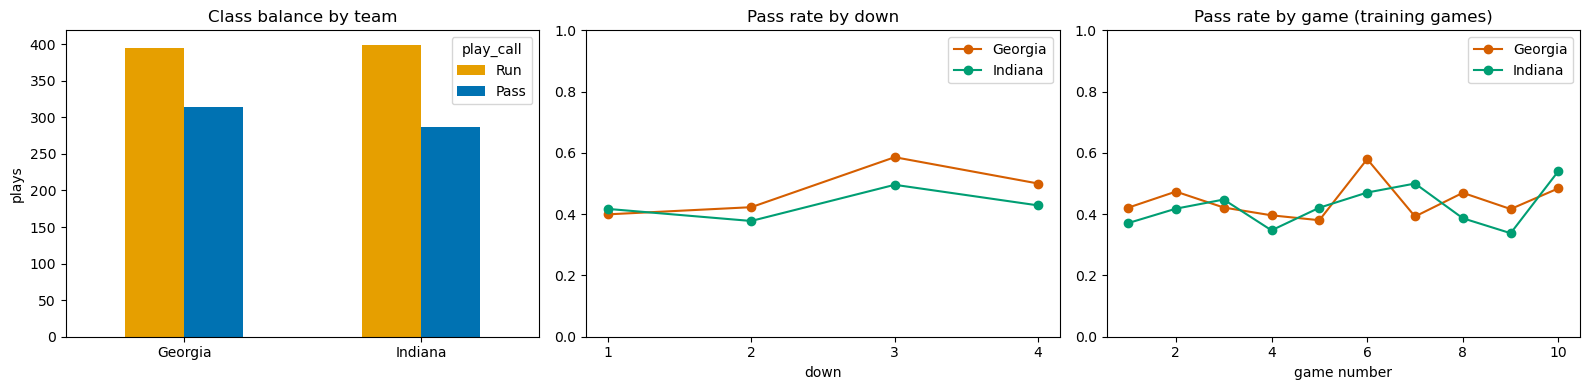

In [40]:
# NullModels (what every real model has to beat)
pass_rate = eda["is_pass"].mean()
print(f"\nNullModel, classification: always predict {'Run' if pass_rate < .5 else 'Pass'} "
      f"-> accuracy {max(pass_rate, 1 - pass_rate):.3f} on the training plays")
print(f"NullModel, regression: always predict the mean {REG_TARGET} = {eda[REG_TARGET].mean():.3f} (R^2 = 0 by definition)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ct = pd.crosstab(eda["requested_team"], eda["play_call"])[["Run", "Pass"]]
ct.plot(kind="bar", ax=axes[0], rot=0, color=[CLASS_COLORS["Run"], CLASS_COLORS["Pass"]])
axes[0].set_title("Class balance by team"); axes[0].set_xlabel(""); axes[0].set_ylabel("plays")

for team, sub in eda.groupby("requested_team"):
    by_down = sub.groupby("down")["is_pass"].mean()
    axes[1].plot(by_down.index, by_down.values, marker="o", color=TEAM_COLORS[team], label=team)
axes[1].set_ylim(0, 1); axes[1].set_xticks([1, 2, 3, 4])
axes[1].set_title("Pass rate by down"); axes[1].set_xlabel("down"); axes[1].legend()

for team, sub in eda.groupby("requested_team"):
    by_game = sub.groupby("game_num")["is_pass"].mean()
    axes[2].plot(by_game.index, by_game.values, marker="o", color=TEAM_COLORS[team], label=team)
axes[2].set_ylim(0, 1)
axes[2].set_title("Pass rate by game (training games)"); axes[2].set_xlabel("game number"); axes[2].legend()

fig.tight_layout(); savefig(fig, "01_overview_teams"); plt.show()

## Feature Audit

This section evaluates the quality of the predictor variables by examining their data types, number of unique values, standard deviation, and percentage of missing observations. Features with zero variance provide no predictive information, while features with more than 30% missing values are flagged for potential removal. In our analysis, no zero-var or high missing attributes were found.

In [41]:
# Create dictionary identifying type of each feature
types = {**{c: "categorical" for c in cat_f}, **{c: "numeric" for c in num_f}, **{c: "binary" for c in bin_f}}
audit = pd.DataFrame({
    "type": pd.Series(types),
    "n_unique": eda[feature_cols].nunique(),
    "std": eda[feature_cols].std().round(3),
    "pct_missing": (eda[feature_cols].isna().mean() * 100).round(1),
}).loc[feature_cols]

# Zero var- feature with the same value for every row doesn't distinguish between plays
# High missing- identify features with more than 30% missing values
zero_var = audit.index[audit["n_unique"] <= 1].tolist()
high_missing = audit.index[audit["pct_missing"] / 100 > MAX_MISSING].tolist()
print("Zero-variance features:", zero_var or "none")
print(f"Features missing more than {MAX_MISSING:.0%}:", high_missing or "none")
print("\nMissing values that remain are first-play-of-game history and each team's first game;")
print("they are imputed inside the modeling pipeline (fit on training data only).")

audit.to_csv(table_dir / "02_feature_audit.csv")
display(audit.sort_values("pct_missing", ascending=False))

Zero-variance features: none
Features missing more than 30%: none

Missing values that remain are first-play-of-game history and each team's first game;
they are imputed inside the modeling pipeline (fit on training data only).


,type,n_unique,std,pct_missing
team_prior_pass_rate_down,numeric,61,0.068,11.8
team_prior_pass_rate,numeric,18,0.021,11.8
prev_call_3,binary,2,0.496,4.3
prev_call_2,binary,2,0.496,2.9
prev_call_1,binary,2,0.496,1.4
prev_yards,numeric,63,9.227,1.4
pass_rate_last5,numeric,11,0.245,1.4
pass_rate_game_so_far,numeric,419,0.129,1.4
yardsToGoal,numeric,99,25.175,0.0
short_yardage,binary,2,0.307,0.0


## Histograms

Histograms are used to examine the distributions of all predictor variables. Features with a small number of unique values are displayed as bar charts, while continuous features are displayed as histograms. This helps identify skewness, unusual distributions, and potential outliers before modeling.

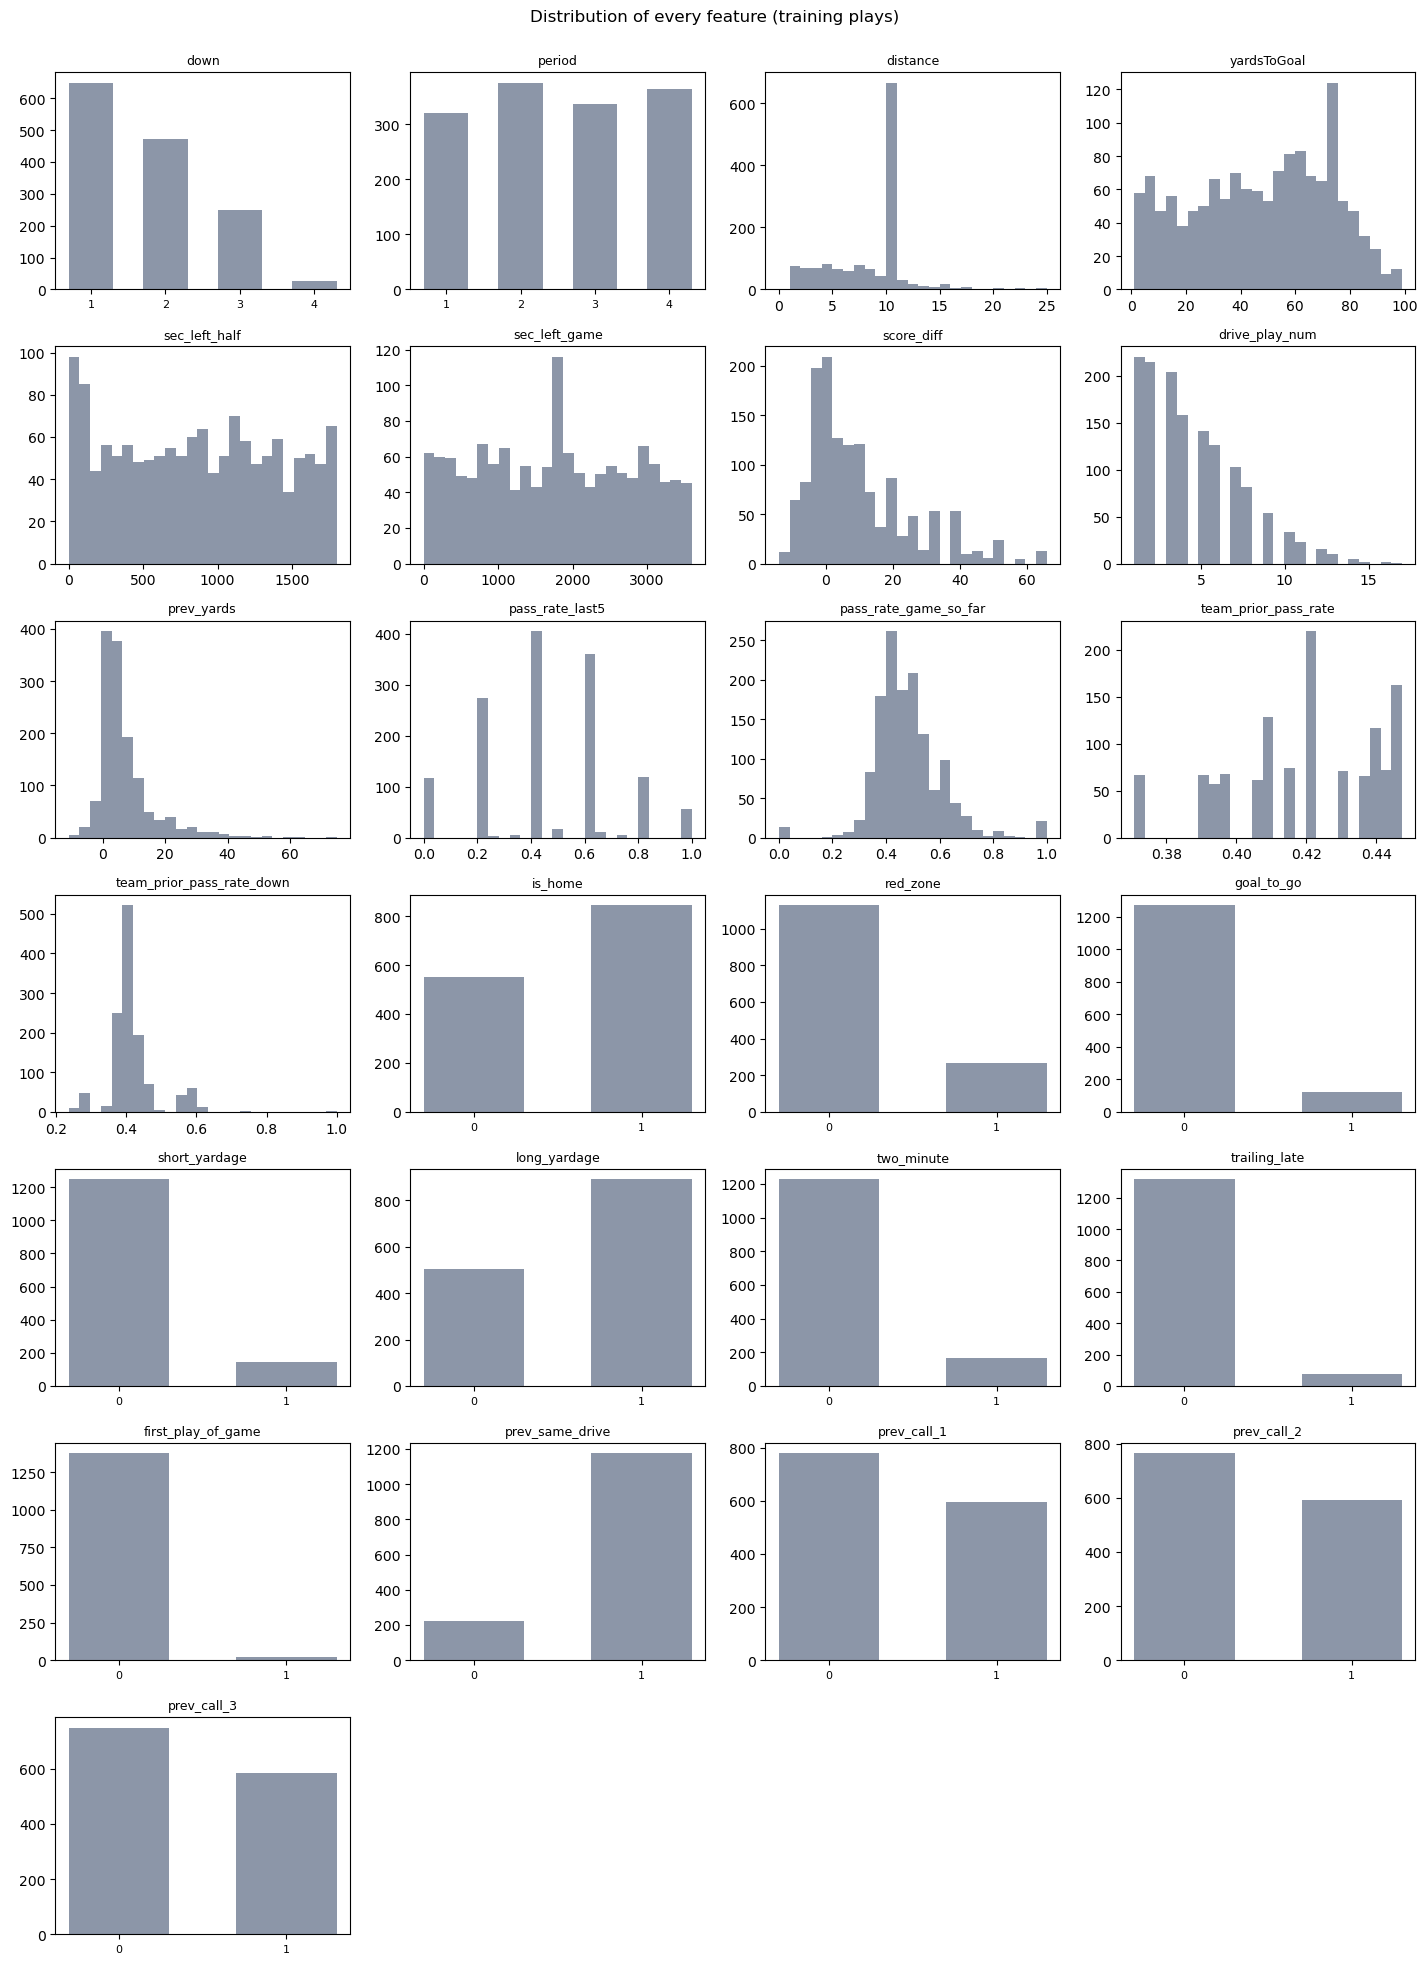

In [76]:
# Create histograms for every predictor
# Bar chart if feature has 8 or fewer unique values, otherwise histogram
fig, axes = make_grid(len(feature_cols))
for ax, f in zip(axes, feature_cols):
    s = eda[f].dropna()
    if s.nunique() <= 8:
        vc = s.value_counts().sort_index()
        ax.bar(vc.index.astype(float), vc.values, color=NEUTRAL, width=0.6)
        ax.set_xticks(vc.index.astype(float))
        ax.set_xticklabels([f"{v:g}" for v in vc.index], fontsize=8)
    else:
        ax.hist(s, bins=25, color=NEUTRAL)
    ax.set_title(f, fontsize=9)
fig.suptitle("Distribution of every feature (training plays)", y=1.0)
fig.tight_layout(); savefig(fig, "03_histograms_features"); plt.show()

## Box Plots and Outliers

Boxplots compare the distributions of continuous predictor variables between run and pass plays. Potential outliers are identified using the interquartile range (IQR) method. Observations outside 1.5 times the IQR are flagged, while observations outside 3 times the IQR are considered more extreme. This analysis helps distinguish legitimate football situations from potential data-quality issues.

In [ ]:
# Continuous numeric features
cont = [f for f in num_f if eda[f].nunique() > 8]

# Create boxplots by plan call (pass or rush)
fig, axes = make_grid(len(cont))
for ax, f in zip(axes, cont):
    data = [eda.loc[eda["is_pass"] == 0, f].dropna(), eda.loc[eda["is_pass"] == 1, f].dropna()]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6,
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.4))
    for patch, c in zip(bp["boxes"], [CLASS_COLORS["Run"], CLASS_COLORS["Pass"]]):
        patch.set_facecolor(c); patch.set_alpha(0.85)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Run", "Pass"])
    ax.set_title(f, fontsize=9)
fig.suptitle("Continuous features by play call (training plays)", y=1.0)
fig.tight_layout(); savefig(fig, "04_boxplots_by_play_call"); plt.show()

# Find outliers with IQR method
def iqr_summary(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series({
        "n": len(s), "min": s.min(), "max": s.max(),
        "outside_1.5_IQR": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        "outside_3_IQR": int(((s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)).sum()),
    })

outliers = pd.DataFrame({c: iqr_summary(eda[c]) for c in cont + ["yardsGained", "ppa"]}).T
outliers["pct_outside_1.5_IQR"] = (outliers["outside_1.5_IQR"] / outliers["n"] * 100).round(1)
outliers.to_csv(table_dir / "04_outliers_iqr.csv")
display(outliers)

,n,min,max,outside_1.5_IQR,outside_3_IQR,pct_outside_1.5_IQR
distance,1395.0,0.000000,25.000000,17.0,0.0,1.2
yardsToGoal,1395.0,1.000000,99.000000,0.0,0.0,0.0
sec_left_half,1395.0,0.000000,1800.000000,0.0,0.0,0.0
sec_left_game,1395.0,0.000000,3600.000000,0.0,0.0,0.0
score_diff,1395.0,-14.000000,66.000000,42.0,0.0,3.0
drive_play_num,1395.0,1.000000,17.000000,20.0,0.0,1.4
prev_yards,1375.0,-11.000000,75.000000,98.0,33.0,7.1
pass_rate_last5,1375.0,0.000000,1.000000,0.0,0.0,0.0
pass_rate_game_so_far,1375.0,0.000000,1.000000,57.0,21.0,4.1
team_prior_pass_rate,1230.0,0.370787,0.447368,0.0,0.0,0.0


## Outlier decisions

We detected outliers using the 1.5 IQR rule on the training plays. 

We kept real plays. The large values in `yardsGained` (up to 75 yards),
`ppa` (-7.2 to 6.6), `prev_yards` and `score_diff` (up to +66) are real
football events: long runs and passes, turnovers, and blowout games. They are
not measurement errors, so removing them would delete real situations a
play-caller faces. For the regression models I will report results on the
raw target and, as a robustness check, on the target capped at its 1st and
99th percentiles. The history features
`pass_rate_game_so_far` and `team_prior_pass_rate_down` show extreme values
because they are computed from few earlier plays (early in a game, or in a
team's first games). These are not errors, but they are noisy.

Dropped data errors. `offenseTimeouts` and `defenseTimeouts` contain
impossible values: offensive timeouts range from -7 to 3 (173 of 1,773
plays, 9.8%, are negative) and defensive from -3 to 3 (12 plays, 0.7%).
A team has 0-3 timeouts per half, so the source appears to be a counter
that is decremented without being reset. Because the non-negative values
come from the same counter, I could not trust them either, and I removed
both features instead of clipping. Timeouts have little effect on
pass/run decisions outside the end of a half, which `sec_left_half` and
`two_minute` already capture.

## Pass/Run classification EDA

How predictable is offensive play selection (Pass v Run) and which pre-snap features provide the most information? The target variable is `is_pass`, where 1 represents a passing play and 0 represents a rushing play.

### Overall Pass/Run distribution in data

First, we established the class balance before modeling. Approximately 56.9% of plays were runs, making Run the majority class.

,plays,percentage
play_call,,
Run,794,56.917563
Pass,601,43.082437


Total plays: 1,395
Pass rate: 43.1%
Run rate: 56.9%


/var/folders/17/mw850ymj2xz726vt4hbjb5nc0000gn/T/ipykernel_35691/678243085.py:21: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  [play_counts.get(0, 0), play_counts.get(1, 0)]


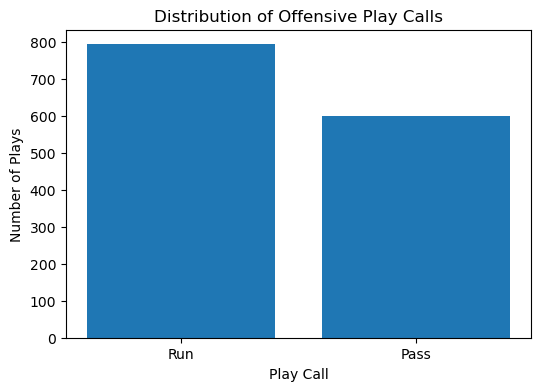

In [79]:
play_counts = eda["play_call"].value_counts()
play_rates = eda["play_call"].value_counts(normalize=True) * 100

classification_summary = pd.DataFrame({
    "plays": play_counts,
    "percentage": play_rates
})

display(classification_summary)

print(f"Total plays: {len(eda):,}")
print(f"Pass rate: {eda['is_pass'].mean():.1%}")
print(f"Run rate: {1 - eda['is_pass'].mean():.1%}")

plt.figure(figsize=(6, 4))

sns = None  # Not using seaborn

plt.bar(
    ["Run", "Pass"],
    [play_counts.get(0, 0), play_counts.get(1, 0)]
)

plt.title("Distribution of Offensive Play Calls")
plt.xlabel("Play Call")
plt.ylabel("Number of Plays")
savefig(fig, "classification_pass_run_distribution")
plt.show()

### Pass rate by feature

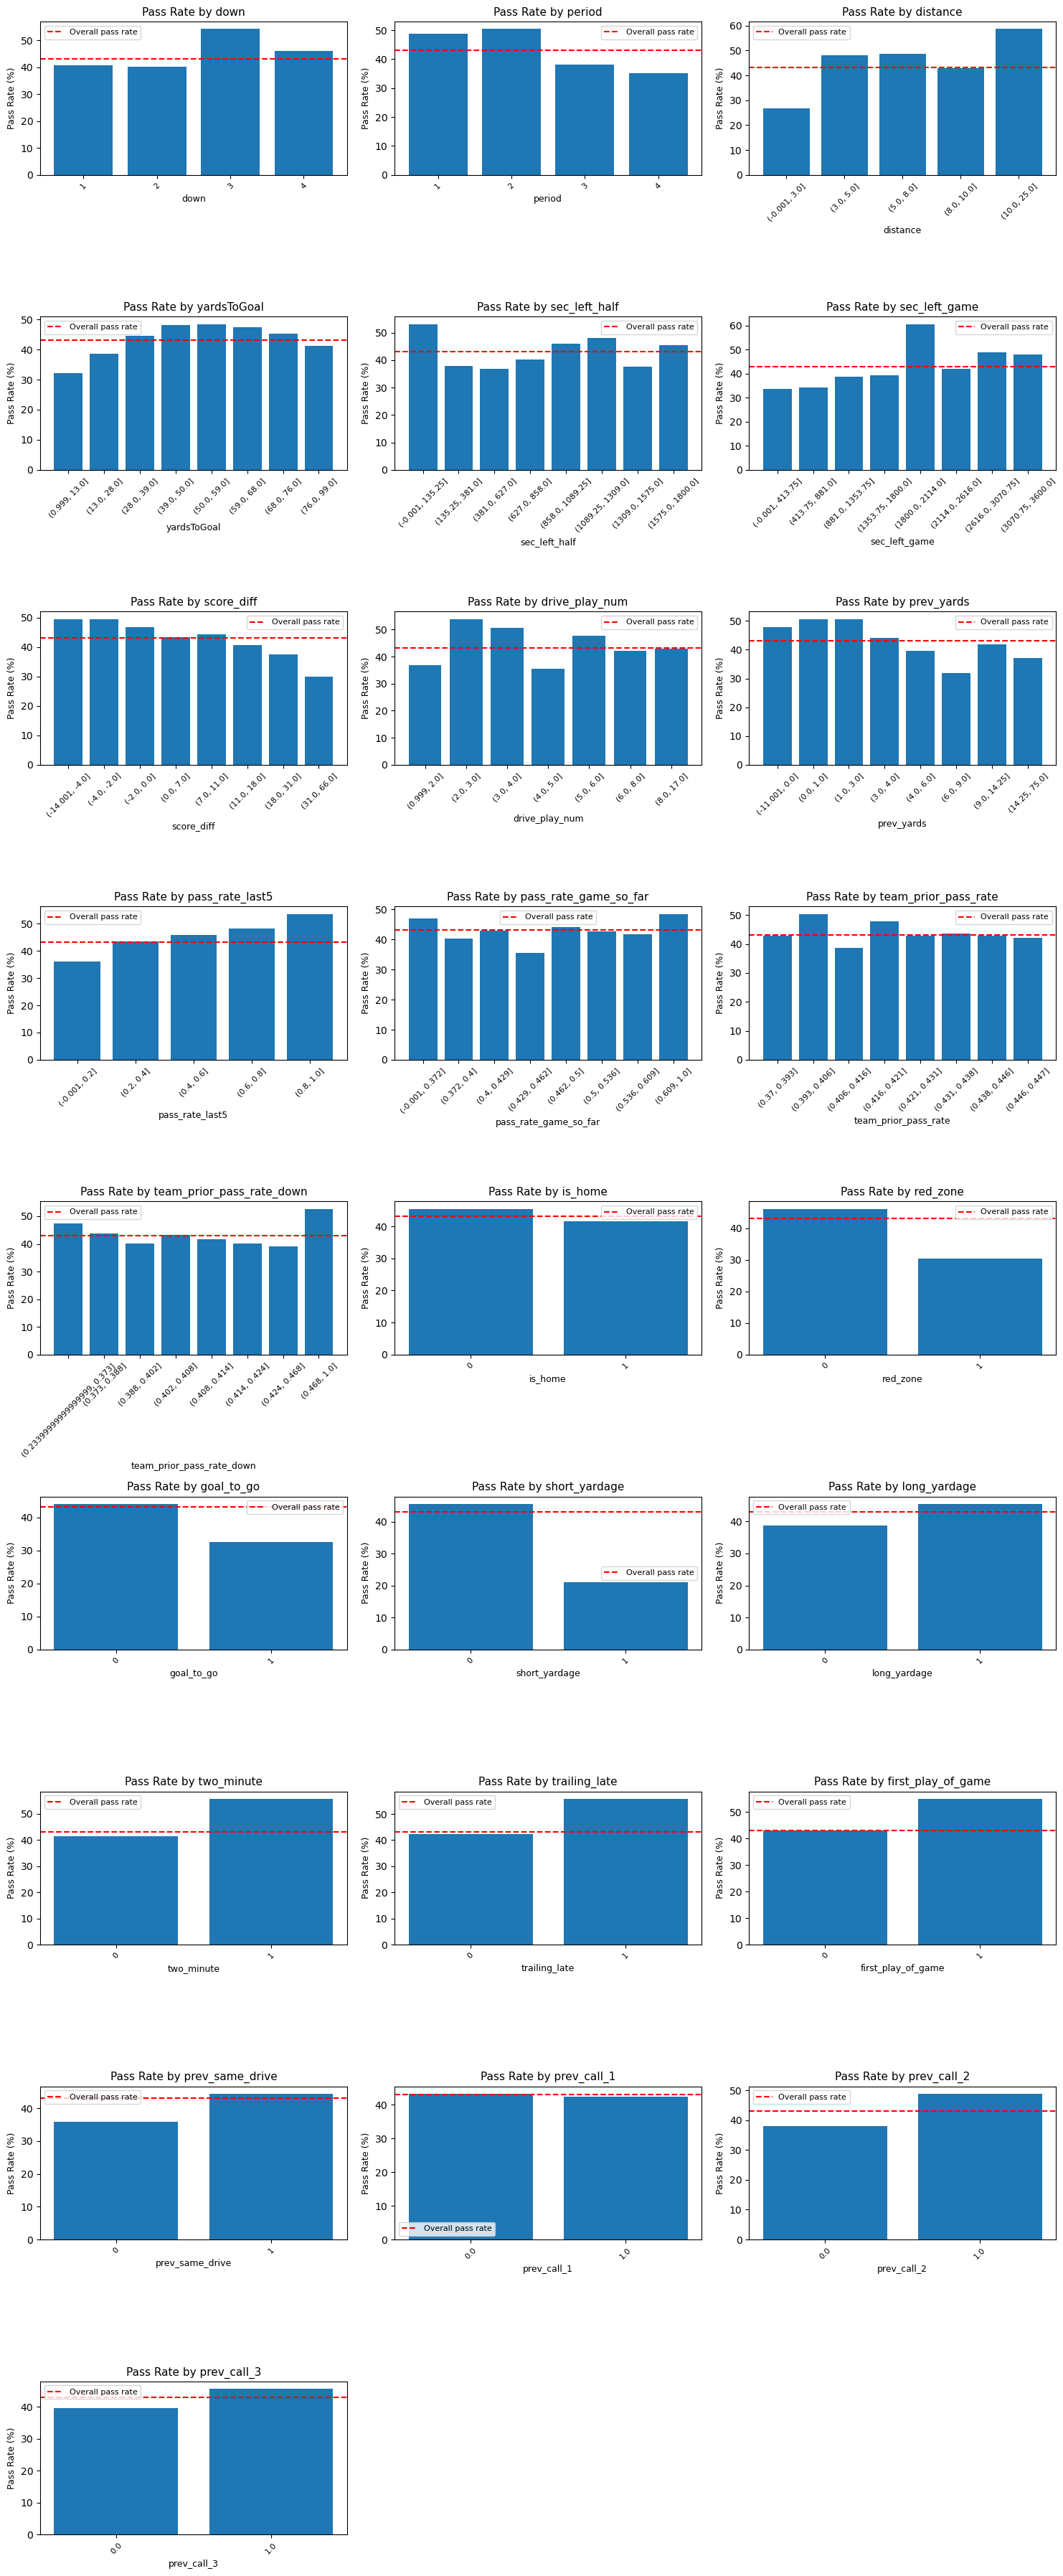

In [ ]:
# Pass rate by feature
def calculate_pass_rate(data, feature, max_bins=8):
    temp = data[[feature, "is_pass"]].dropna().copy()

    # Group numeric features with many unique values into bins
    if (
        pd.api.types.is_numeric_dtype(temp[feature])
        and temp[feature].nunique() > max_bins
    ):
        temp["feature_group"] = pd.qcut(
            temp[feature],
            q=max_bins,
            duplicates="drop"
        )
    else:
        temp["feature_group"] = temp[feature]

    result = (
        temp.groupby("feature_group", observed=True)["is_pass"]
        .agg(["mean", "count"])
        .reset_index()
    )

    result["pass_rate"] = result["mean"] * 100

    return result.rename(columns={
        "feature_group": "group",
        "count": "n"
    })[["group", "n", "pass_rate"]]

classification_features = [
    f for f in feature_cols
    if f in eda.columns and f != "is_pass"
]

n_cols = 3
n_rows = int(np.ceil(len(classification_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows)
)

axes = np.array(axes).flatten()

overall_pass_rate = eda["is_pass"].mean() * 100

for i, feature in enumerate(classification_features):
    result = calculate_pass_rate(eda, feature)

    axes[i].bar(
        result["group"].astype(str),
        result["pass_rate"]
    )

    axes[i].axhline(
        overall_pass_rate,
        color="red",
        linestyle="--",
        label="Overall pass rate"
    )

    axes[i].set_title(f"Pass Rate by {feature}", fontsize=11)
    axes[i].set_xlabel(feature, fontsize=9)
    axes[i].set_ylabel("Pass Rate (%)", fontsize=9)
    axes[i].tick_params(axis="x", labelrotation=45, labelsize=8)
    axes[i].legend(fontsize=8)

# Remove unused subplot spaces
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
savefig(fig, "classification_passrate_by_feature")
plt.show()

### Pass rate by down and distance combinations

After examining pass rate per feature, we can see which features may have pass rates that vary substantially across its groups, indicating a potentially helpful relationship in play selection.

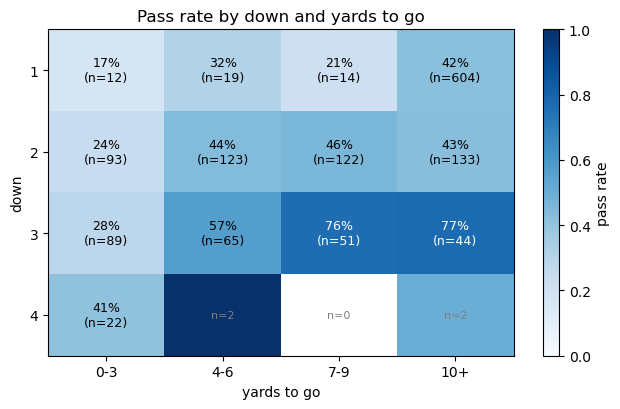

In [ ]:
# Pass rate by down and distance
d = eda.copy()
d["dist_bin"] = pd.cut(d["distance"], [-1, 3, 6, 9, 100], labels=["0-3", "4-6", "7-9", "10+"])
rate = d.pivot_table(index="down", columns="dist_bin", values="is_pass", aggfunc="mean", observed=False)
cnt = d.pivot_table(index="down", columns="dist_bin", values="is_pass", aggfunc="size", observed=False).fillna(0)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
im = ax.imshow(rate.values, vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks(range(rate.shape[1])); ax.set_xticklabels(rate.columns)
ax.set_yticks(range(rate.shape[0])); ax.set_yticklabels(rate.index)
ax.set_xlabel("yards to go"); ax.set_ylabel("down"); ax.grid(False)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        r, n = rate.values[i, j], int(cnt.values[i, j])
        if n < 10 or np.isnan(r):
            ax.text(j, i, f"n={n}", ha="center", va="center", fontsize=8, color="gray")
        else:
            ax.text(j, i, f"{r:.0%}\n(n={n})", ha="center", va="center", fontsize=9,
                    color="white" if r > 0.6 else "black")
ax.set_title("Pass rate by down and yards to go")
fig.colorbar(im, ax=ax, label="pass rate")
fig.tight_layout(); savefig(fig, "05_pass_rate_down_by_distance"); plt.show()

We can examine the heatmap, we looked for combinations of down and distance where pass rates are especially high or low. 

### AUC

In [80]:
from sklearn.metrics import roc_auc_score

def calculate_univariate_auc(data, feature, target="is_pass"):
    temp = data[[feature, target]].dropna()

    # Skip features with only one unique value
    if temp[feature].nunique() < 2:
        return np.nan

    # AUC requires a numeric feature
    if not pd.api.types.is_numeric_dtype(temp[feature]):
        return np.nan

    auc = roc_auc_score(temp[target], temp[feature])

    # Strength measures separation regardless of direction
    strength = max(auc, 1 - auc)

    return auc, strength

auc_features = [
    f for f in num_f + bin_f
    if f in eda.columns and f != "is_pass"
]

auc_results = []

for feature in auc_features:
    result = calculate_univariate_auc(eda, feature)

    if isinstance(result, tuple):
        auc, strength = result

        auc_results.append({
            "feature": feature,
            "auc": auc,
            "strength": strength,
            "direction": "Pass" if auc > 0.5 else "Run"
        })

auc_df = pd.DataFrame(auc_results)

auc_df = auc_df.sort_values(
    "strength",
    ascending=False
).reset_index(drop=True)

display(auc_df)

,feature,auc,strength,direction
0,sec_left_game,0.565371,0.565371,Pass
1,score_diff,0.434763,0.565237,Run
2,prev_yards,0.441504,0.558496,Run
3,prev_call_2,0.554981,0.554981,Pass
4,distance,0.551872,0.551872,Pass
5,pass_rate_last5,0.550832,0.550832,Pass
6,red_zone,0.450259,0.549741,Run
7,short_yardage,0.452742,0.547258,Run
8,yardsToGoal,0.535847,0.535847,Pass
9,long_yardage,0.531523,0.531523,Pass


The univariate AUC analysis evaluated how well individual features distinguish between Pass and Run plays. Overall, no individual feature demonstrated strong predictive ability, with AUC strengths ranging from approximately 0.50 to 0.57.

The strongest individual predictors were sec_left_game (0.565), score_diff (0.565), and prev_yards (0.558). Game time and score differential showed opposite relationships with play selection: more time remaining was associated with a greater tendency to pass, while higher score differentials were associated with a greater tendency to run. Recent play history, including prev_call_2 and pass_rate_last5, also demonstrated modest predictive signal.

Several features, including team_prior_pass_rate_down, first_play_of_game, and prev_call_1, had AUC strengths close to 0.50, indicating little individual ability to distinguish between pass and run plays.

Overall, the results suggest that offensive play selection is not strongly explained by any single predictor. Combining multiple features and capturing interactions between game situations, team tendencies, and recent play history may improve classification performance.

### Feature correlation

Before selecting predictors for classification, we examine correlations between features to identify potentially redundant information.

Highly correlated predictors may represent similar aspects of a football situation. Removing redundant features can simplify the model and reduce potential multicollinearity.

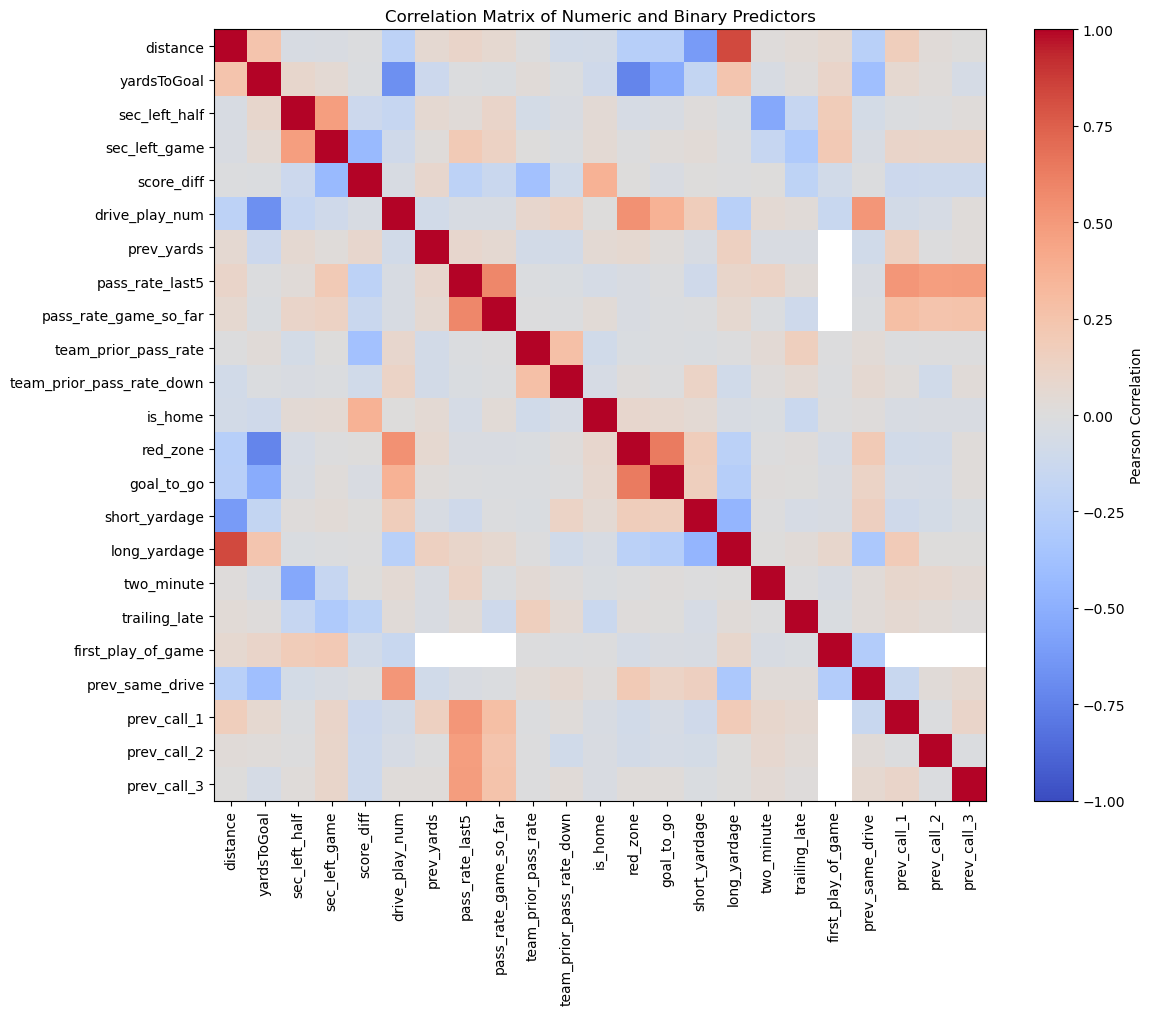

In [ ]:
corr_features = [
    f for f in num_f + bin_f
    if f in eda.columns
]

corr_matrix = eda[corr_features].corr(method="pearson")

plt.figure(figsize=(12, 10))

plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(corr_features)),
    corr_features,
    rotation=90
)

plt.yticks(
    range(len(corr_features)),
    corr_features
)

plt.title("Correlation Matrix of Numeric and Binary Predictors")
plt.tight_layout()
savefig(fig, "classification_heatmap")
plt.show()

In [ ]:
# Identify highly correlated pairs with correlation >= 0.80

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

correlated_pairs = (
    upper.stack()
    .reset_index()
)

correlated_pairs.columns = [
    "feature_a",
    "feature_b",
    "correlation"
]

correlated_pairs["abs_correlation"] = (
    correlated_pairs["correlation"].abs()
)

correlated_pairs = (
    correlated_pairs[
        correlated_pairs["abs_correlation"] >= CORR_THRESHOLD
    ]
    .sort_values("abs_correlation", ascending=False)
    .reset_index(drop=True)
)

display(correlated_pairs)

,feature_a,feature_b,correlation,abs_correlation
0,distance,long_yardage,0.833113,0.833113
1,yardsToGoal,red_zone,-0.729141,0.729141
2,yardsToGoal,drive_play_num,-0.679380,0.679380
3,red_zone,goal_to_go,0.639158,0.639158
4,distance,short_yardage,-0.612556,0.612556


We identified highly correlated pairs with correlation >= 0.80, which may contain redundant information. 

### Feature selection

In [ ]:
def select_classification_features(
    data,
    features,
    corr_threshold=CORR_THRESHOLD,
    prefer_drop=None,
    manual_keep=None
):
    prefer_drop = prefer_drop or []
    manual_keep = manual_keep or []

    # Separate numeric/binary features from nominal categories
    numeric_features = [
        f for f in features
        if f in (num_f + bin_f)
        and f in data.columns
    ]

    categorical_features = [
        f for f in features
        if f in cat_f
        and f in data.columns
    ]

    # Calculate predictor correlations
    corr = data[numeric_features].corr().abs()

    # Calculate individual association with the target
    association = (
        data[numeric_features]
        .corrwith(data["is_pass"])
        .abs()
        .fillna(0)
    )

    kept = numeric_features.copy()
    dropped = []

    while True:
        current_corr = corr.loc[kept, kept].copy()

        # Ignore the diagonal
        np.fill_diagonal(current_corr.values, 0)

        if current_corr.empty or current_corr.max().max() < corr_threshold:
            break

        feature_a, feature_b = current_corr.stack().idxmax()

        # Do not remove either feature if both are manually protected
        if feature_a in manual_keep and feature_b in manual_keep:
            corr.loc[feature_a, feature_b] = 0
            corr.loc[feature_b, feature_a] = 0
            continue

        if feature_a in manual_keep:
            remove = feature_b
        elif feature_b in manual_keep:
            remove = feature_a
        elif feature_a in prefer_drop:
            remove = feature_a
        elif feature_b in prefer_drop:
            remove = feature_b
        elif association[feature_a] >= association[feature_b]:
            remove = feature_b
        else:
            remove = feature_a

        kept.remove(remove)
        dropped.append(remove)

    # Add nominal categorical features back
    final_features = kept + categorical_features

    return final_features, dropped

In [52]:
classification_candidates = [
    f for f in feature_cols
    if f in eda.columns and f != "is_pass"
]

classification_features, classification_dropped = (
    select_classification_features(
        data=eda,
        features=classification_candidates,
        corr_threshold=CORR_THRESHOLD,
        prefer_drop=PREFER_DROP,
        manual_keep=MANUAL_KEEP
    )
)

print("Classification features retained:")
print(classification_features)

print("\nFeatures removed:")
print(classification_dropped)

print(f"\nNumber retained: {len(classification_features)}")
print(f"Number removed: {len(classification_dropped)}")

Classification features retained:
['distance', 'yardsToGoal', 'sec_left_half', 'sec_left_game', 'score_diff', 'prev_yards', 'pass_rate_last5', 'pass_rate_game_so_far', 'team_prior_pass_rate', 'team_prior_pass_rate_down', 'is_home', 'goal_to_go', 'two_minute', 'trailing_late', 'first_play_of_game', 'prev_same_drive', 'prev_call_1', 'prev_call_2', 'prev_call_3', 'down', 'period']

Features removed:
['long_yardage', 'red_zone', 'drive_play_num', 'short_yardage']

Number retained: 21
Number removed: 4


When two features are highly correlated, we kept the feature with the stronger individual relationship with the classification target. We preserve the features with a clear football interpretation, regardless of individual association. We also kept the categorical features for modeling where they can be appropriately encoded. This is a preliminary EDA-based selection method, not a substitute for feature selection and validation during model development.

In [54]:
decisions = {
    "settings": {
        "CORR_THRESHOLD": CORR_THRESHOLD,
        "MAX_MISSING": MAX_MISSING,
        "PREFER_DROP": PREFER_DROP,
        "eda_split": "train",
        "target": "is_pass"
    },

    "dropped": {
        "zero_variance": zero_var,
        "high_missing": high_missing,
        "correlated": classification_dropped,
    },

    "classification": {
        "features": classification_features,
        "categorical": [f for f in cat_f if f in classification_features],
        "numeric": [f for f in num_f if f in classification_features],
        "binary": [f for f in bin_f if f in classification_features],
    },

    "targets": fl["targets"],
    "optional_categorical": fl.get("optional_categorical", []),
    "group_column": fl["group_column"],
    "split_column": fl["split_column"],
}

# Save feature-selection decisions
with open(processed_dir / "classification_feature_lists_after_eda.json", "w") as f:
    json.dump(decisions, f, indent=2)

n_kept = len(classification_features)

print(f"Saved {processed_dir / 'classification_feature_lists_after_eda.json'}")
print(f"Classification features kept: {n_kept}")

# Report saved figures and tables
print("Figures:", len(list(fig_dir.glob("*.png"))), "in", fig_dir)
print("Tables:", len(list(table_dir.glob("*.csv"))), "in", table_dir)

Saved /Users/gracynkim/Desktop/school/fall '26/CSCI 6360/college-football-play-prediction/data/processed/classification_feature_lists_after_eda.json
Classification features kept: 21
Figures: 11 in /Users/gracynkim/Desktop/school/fall '26/CSCI 6360/college-football-play-prediction/reports/figures
Tables: 8 in /Users/gracynkim/Desktop/school/fall '26/CSCI 6360/college-football-play-prediction/reports/tables


## PPA regression EDA

### PPA distribution

In [ ]:
# PPA summary statistics
ppa_summary = eda[REG_TARGET].describe()

display(ppa_summary)

count    1394.000000
mean        0.282634
std         1.346450
min        -7.222469
25%        -0.430215
50%         0.075470
75%         0.936956
max         6.596680
Name: ppa, dtype: float64

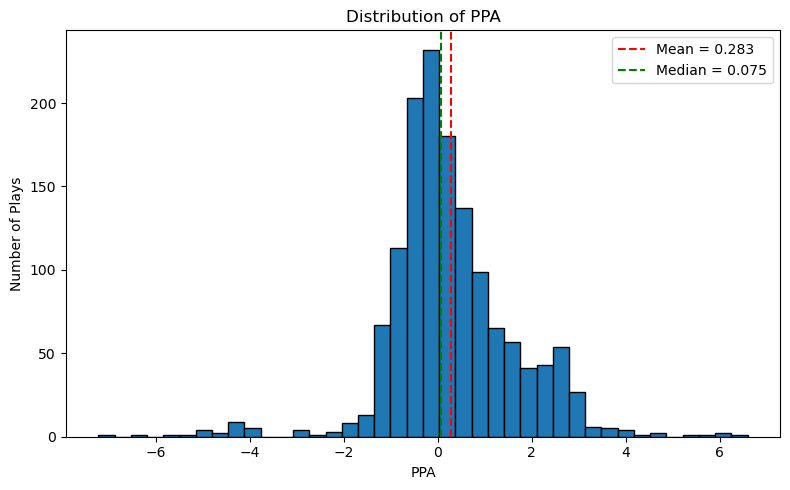

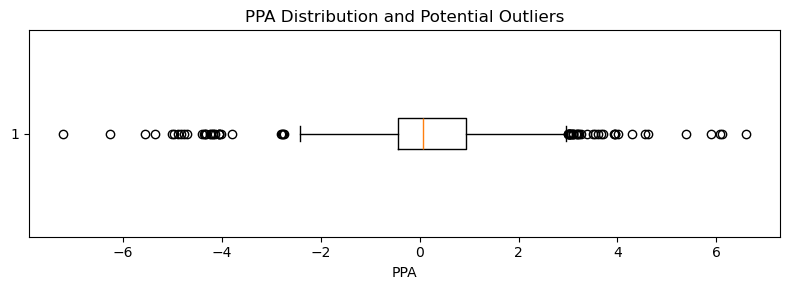

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    eda[REG_TARGET].dropna(),
    bins=40,
    edgecolor="black"
)

plt.axvline(
    eda[REG_TARGET].mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {eda[REG_TARGET].mean():.3f}"
)

plt.axvline(
    eda[REG_TARGET].median(),
    color="green",
    linestyle="--",
    label=f"Median = {eda[REG_TARGET].median():.3f}"
)

plt.title("Distribution of PPA")
plt.xlabel("PPA")
plt.ylabel("Number of Plays")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))

plt.boxplot(
    eda[REG_TARGET].dropna(),
    vert=False
)

plt.title("PPA Distribution and Potential Outliers")
plt.xlabel("PPA")
plt.tight_layout()

plt.tight_layout()

savefig(plt.gcf(), "ppa_histogram")

plt.show()

The distribution of PPA is centered and concentrated around zero, with slight right skew and fairly long tails. The mean is 0.283 and median 0.075, showing that larger positive PPA values are pulling the mean up. There are several potential outliers, both negative and positive. These high values may represent meaningful high impact plays, so we will keep them for initial regression analysis. 

### PPA for Pass/Run plays

,play_call,count,mean,median,std
0,Pass,600,0.371649,0.222044,1.592620
1,Run,794,0.215369,-0.013949,1.121686


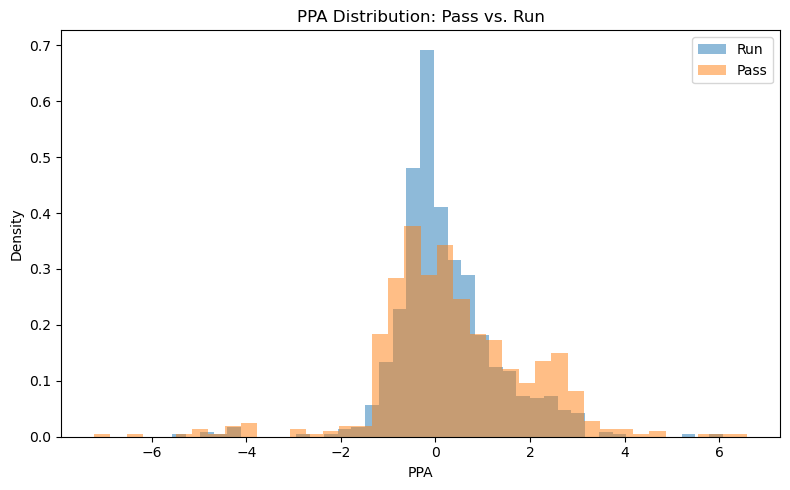

In [ ]:
# Summary statistics by play call
ppa_by_play = (
    eda.groupby("play_call")[REG_TARGET]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

display(ppa_by_play)

plt.figure(figsize=(8, 5))

for play in ["Run", "Pass"]:
    values = eda.loc[eda["play_call"] == play, REG_TARGET].dropna()

    plt.hist(
        values,
        bins=40,
        alpha=0.5,
        density=True,
        label=play
    )

plt.title("PPA Distribution: Pass vs. Run")
plt.xlabel("PPA")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()

savefig(plt.gcf(), "ppa_by_play_call")

plt.show()

### Simple linear and quadratic regression

In [ ]:
# Simple linear regression for each numeric/binary feature
# Also fit a quadratic model to check for potential nonlinear relationships.

reg_numeric_features = [
    f for f in (num_f + bin_f)
    if f in eda.columns
    and f not in [REG_TARGET, "is_pass", "yardsGained"]
]

rows = []

for f in reg_numeric_features:
    d = eda[[f, REG_TARGET]].dropna()

    if d[f].nunique() < 2:
        continue

    x = d[f].astype(float)
    y = d[REG_TARGET].astype(float)

    # Linear regression
    lr = stats.linregress(x, y)

    r2_quad = np.nan

    # Quadratic regression (only if feature has at least 3 unique values)
    if d[f].nunique() > 2 and x.std() > 0:
        z = (x - x.mean()) / x.std()

        coefficients = np.polyfit(z, y, 2)
        pred = np.polyval(coefficients, z)

        ss_res = ((y - pred) ** 2).sum()
        ss_tot = ((y - y.mean()) ** 2).sum()

        if ss_tot > 0:
            r2_quad = 1 - ss_res / ss_tot

    rows.append({
        "feature": f,
        "n": len(d),
        "b0": lr.intercept,
        "b1": lr.slope,
        "r": lr.rvalue,
        "R2": lr.rvalue ** 2,
        "p_value": lr.pvalue,
        "R2_quadratic": r2_quad
    })

simple_reg = (
    pd.DataFrame(rows)
    .set_index("feature")
    .sort_values("R2", ascending=False)
)

# Improvement from adding a quadratic term
simple_reg["R2_gain_from_quadratic"] = (
    simple_reg["R2_quadratic"] - simple_reg["R2"]
)

# Save results
simple_reg.to_csv(table_dir / "06_simple_regression_per_feature.csv")

display(simple_reg.round(4).head(15))

print(
    f"\nBest single-feature R^2 for {REG_TARGET}: "
    f"{simple_reg['R2'].max():.4f} ({simple_reg['R2'].idxmax()})"
)

curved = simple_reg[
    simple_reg["R2_gain_from_quadratic"] > 0.01
]

print(
    "Features where a quadratic term adds > 0.01 R^2:",
    curved.index.tolist() or "none"
)


,n,b0,b1,r,R2,p_value,R2_quadratic,R2_gain_from_quadratic
feature,,,,,,,,
long_yardage,1394,0.4132,-0.2045,-0.0730,0.0053,0.0064,NaN,NaN
is_home,1394,0.1655,0.1935,0.0702,0.0049,0.0087,NaN,NaN
prev_yards,1374,0.3472,-0.0094,-0.0642,0.0041,0.0173,0.0048,0.0007
score_diff,1394,0.2298,0.0054,0.0638,0.0041,0.0173,0.0044,0.0004
team_prior_pass_rate,1229,1.9761,-4.0197,-0.0620,0.0038,0.0297,0.0045,0.0007
red_zone,1394,0.2435,0.2053,0.0599,0.0036,0.0253,NaN,NaN
drive_play_num,1394,0.1855,0.0216,0.0476,0.0023,0.0754,0.0027,0.0005
goal_to_go,1394,0.2642,0.2085,0.0439,0.0019,0.1010,NaN,NaN
sec_left_half,1394,0.2002,0.0001,0.0385,0.0015,0.1510,0.0018,0.0003



Best single-feature R^2 for ppa: 0.0053 (long_yardage)
Features where a quadratic term adds > 0.01 R^2: none


Simple linear regression models were fitted for each numeric and binary predictor to examine its individual relationship with PPA. Quadratic models were also fitted to investigate potential nonlinear relationships. The resulting R² values indicate how much variation in PPA can be explained by each feature individually. The improvement in R² from the quadratic models provides an initial indication of whether a nonlinear relationship may exist.

### Scatterplots 

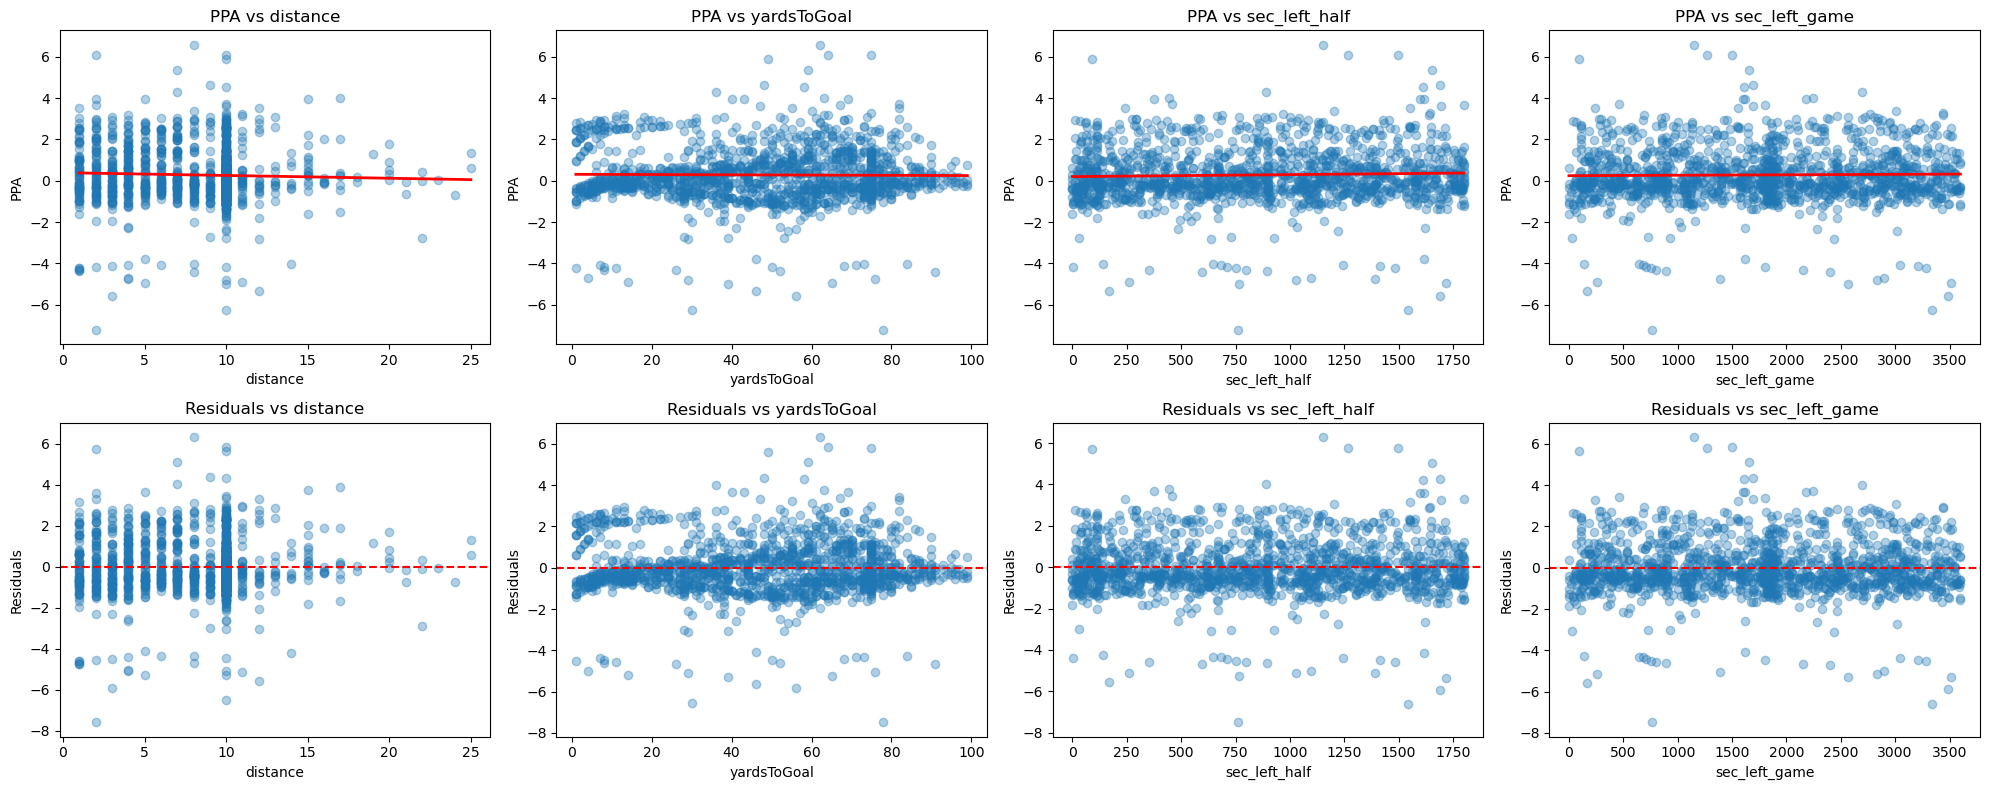

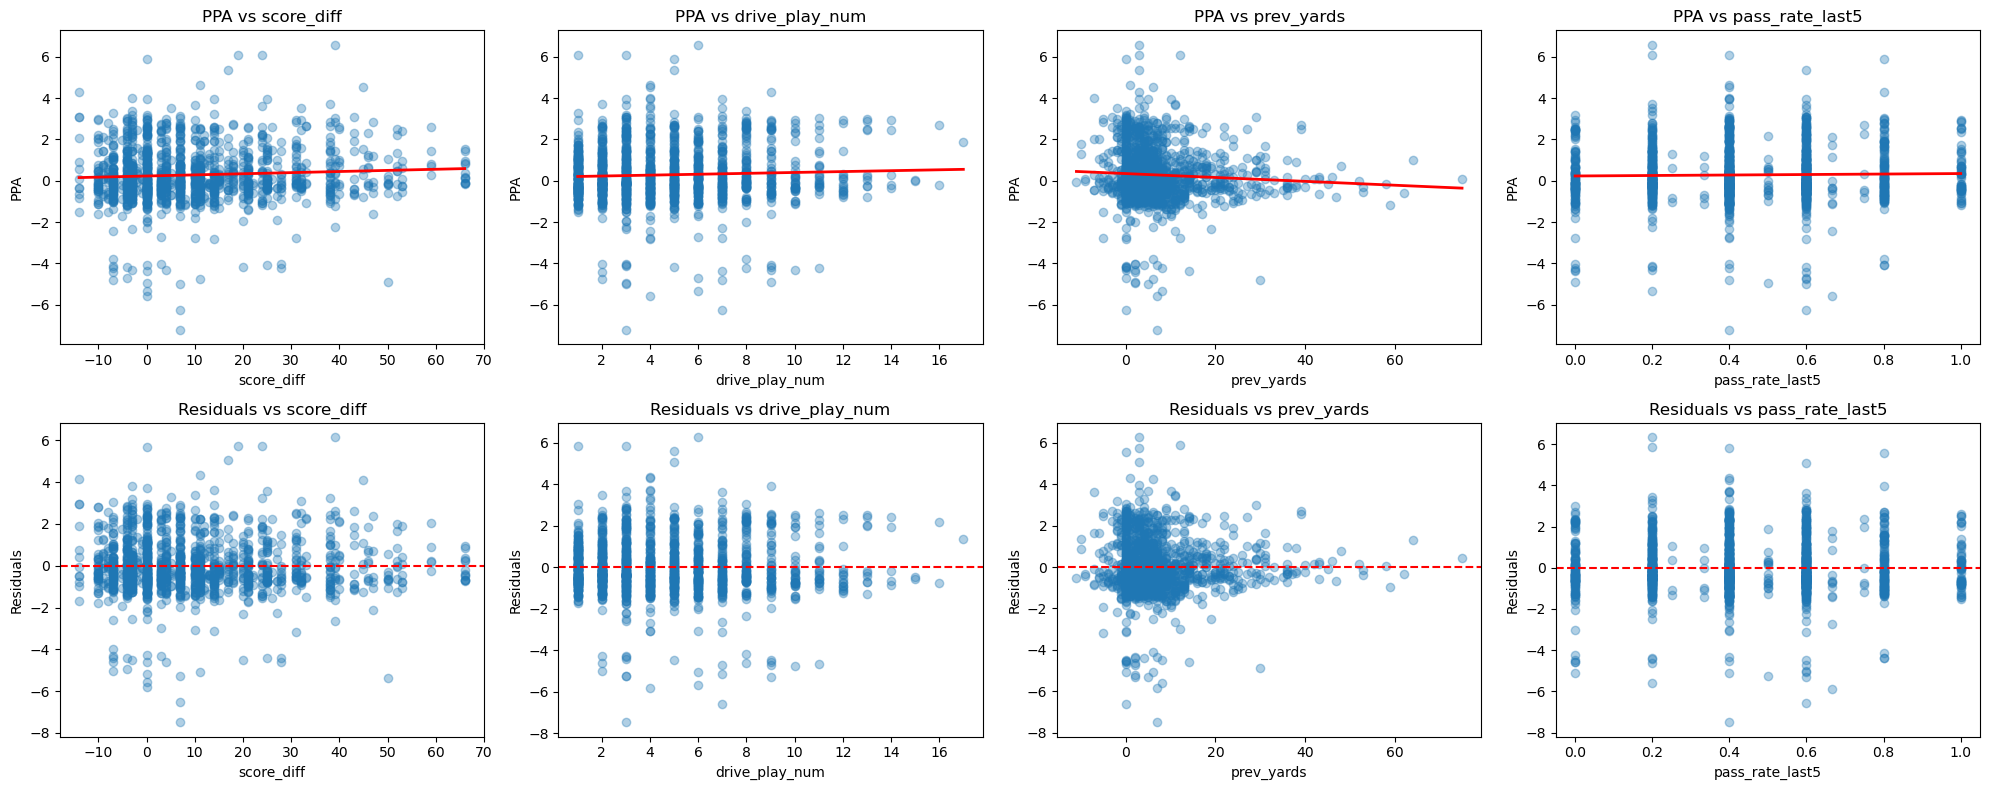

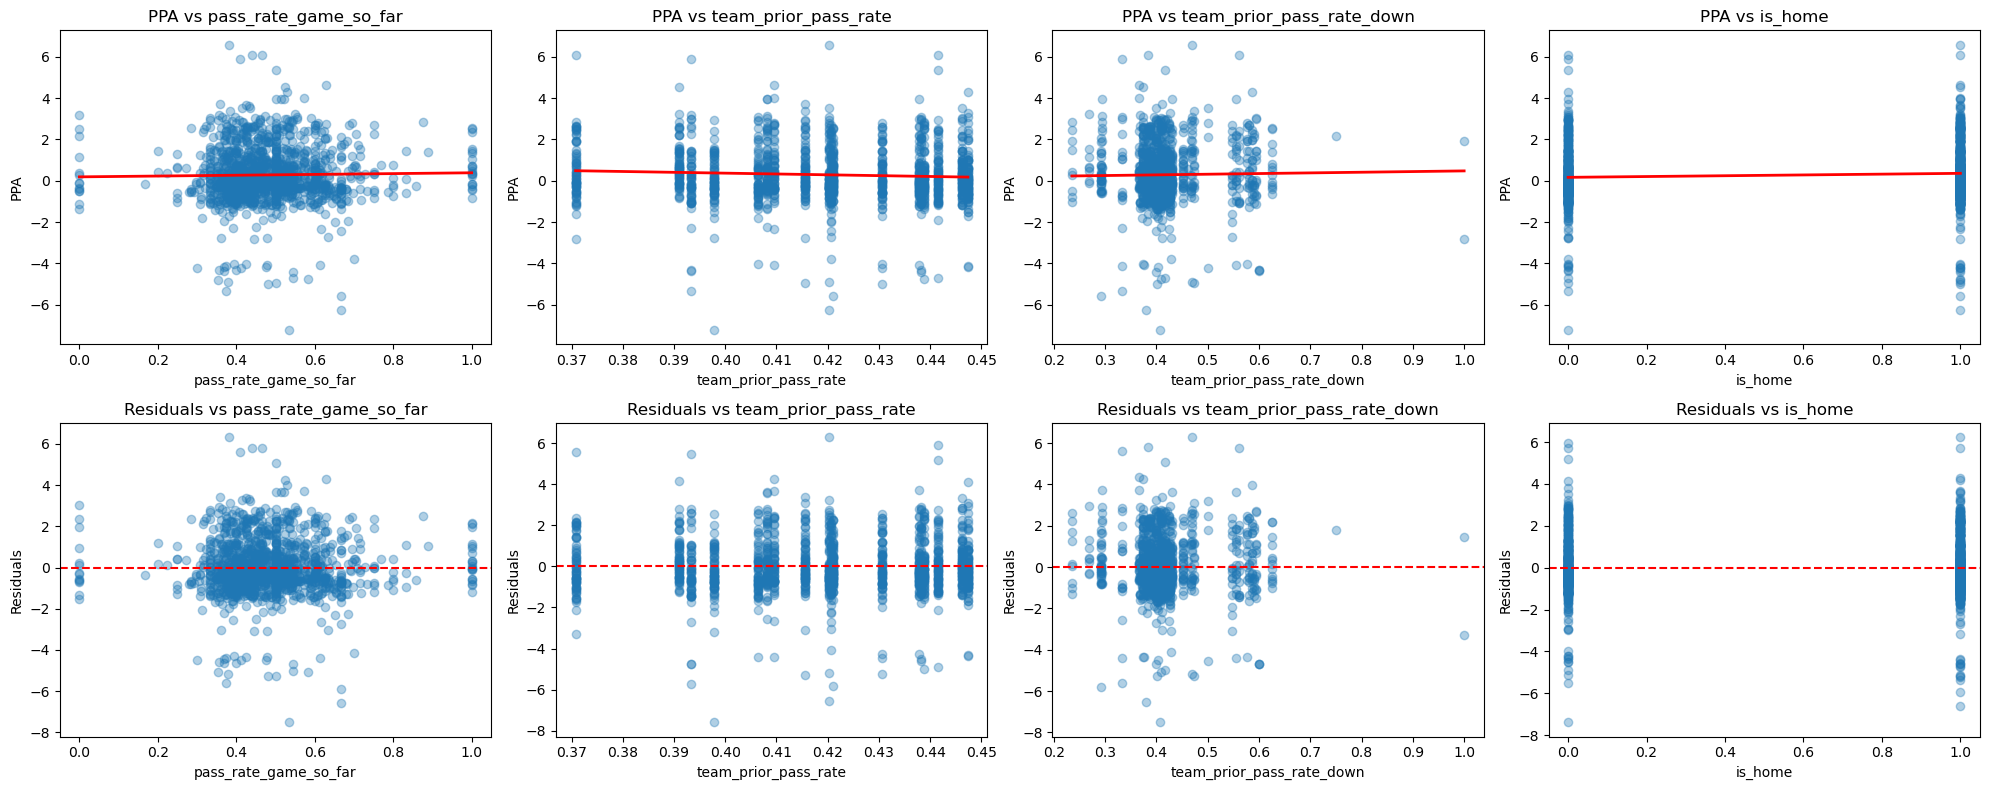

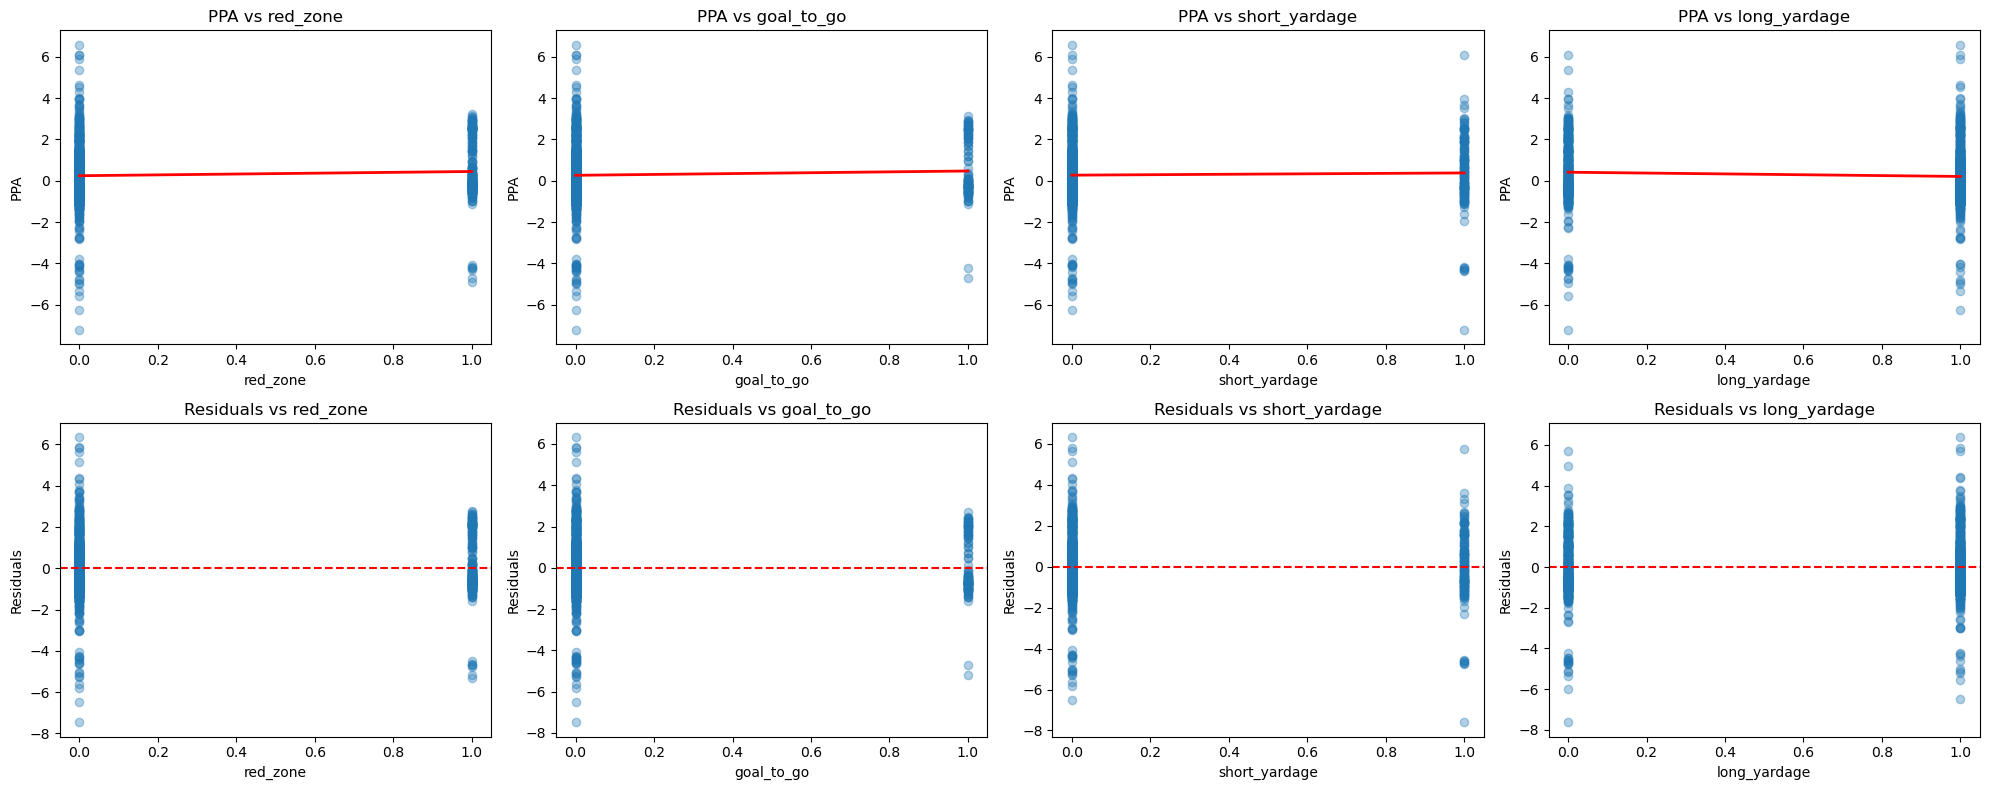

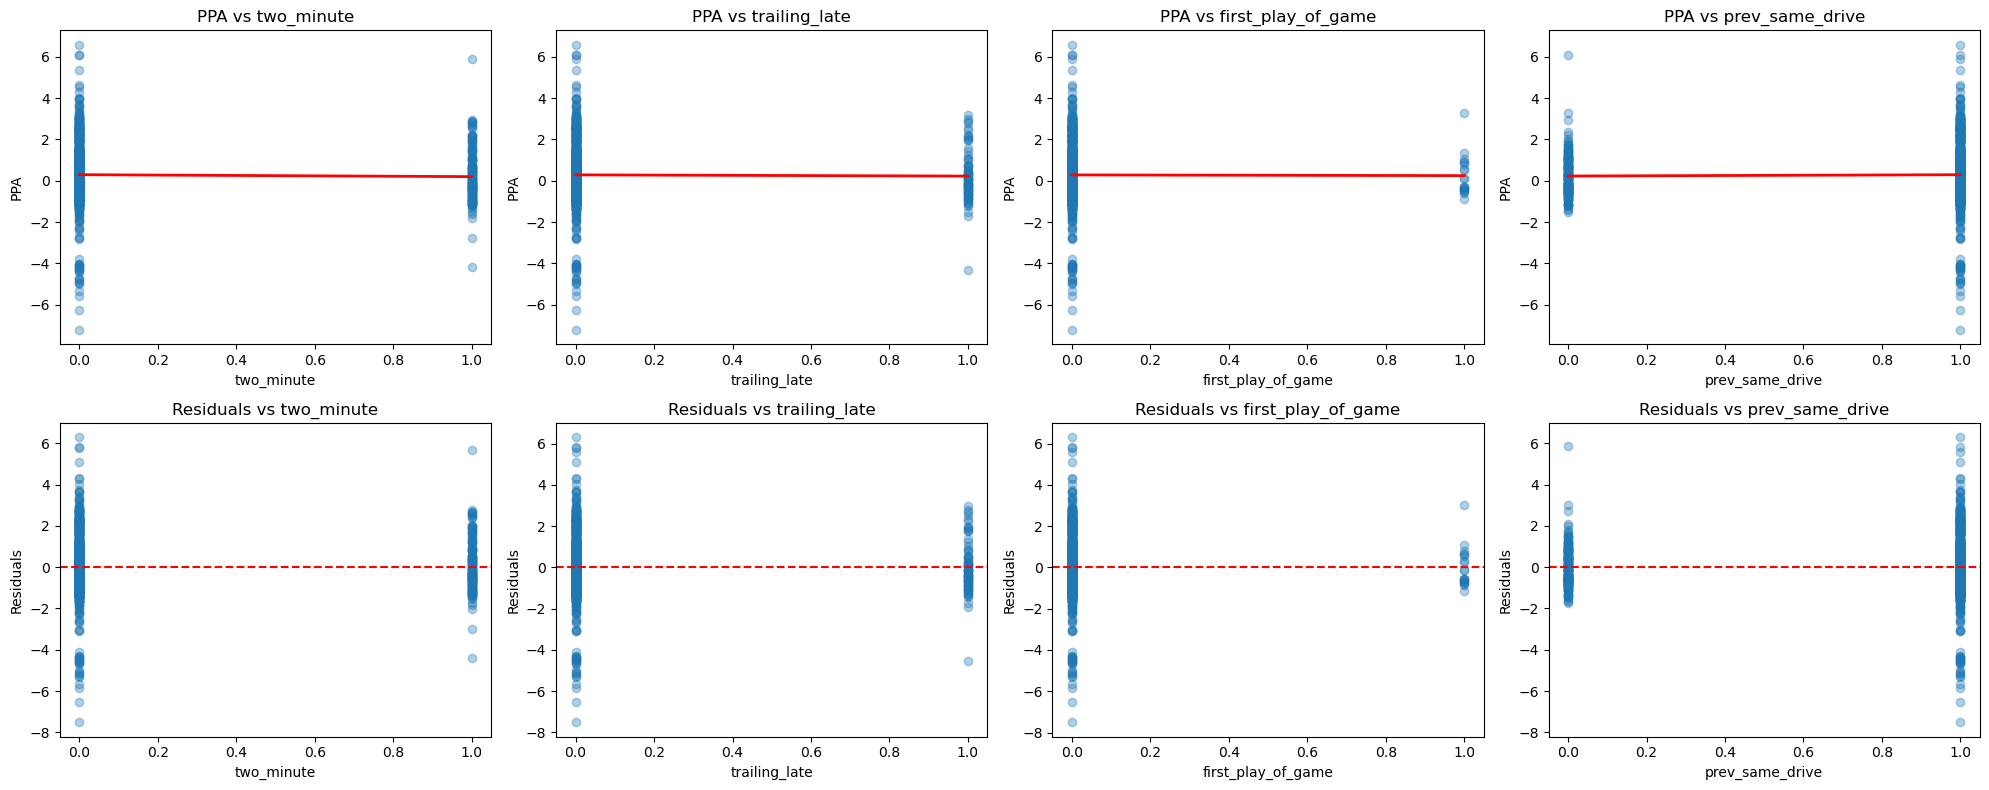

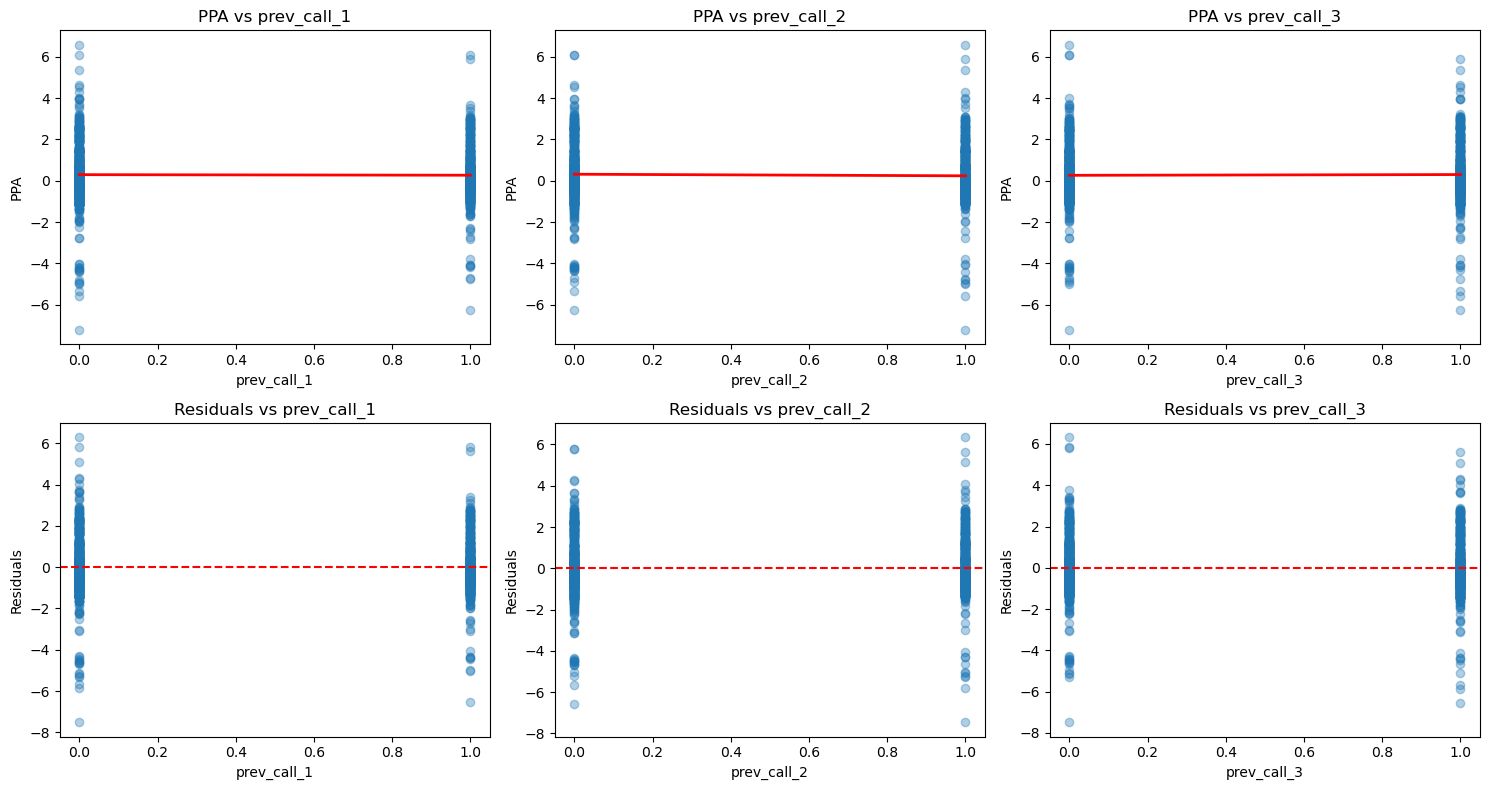

In [ ]:
# Scatterplots and residual plots: 4 features per row

plots_per_row = 4
features_per_figure = plots_per_row

for start in range(0, len(reg_numeric_features), features_per_figure):

    features = reg_numeric_features[start:start + features_per_figure]

    # Two plots per feature: scatterplot and residual plot
    fig, axes = plt.subplots(
        2,
        len(features),
        figsize=(5 * len(features), 8)
    )

    if len(features) == 1:
        axes = axes.reshape(2, 1)

    for j, f in enumerate(features):

        d = eda[[f, REG_TARGET]].dropna()

        if d[f].nunique() < 2:
            axes[0, j].set_visible(False)
            axes[1, j].set_visible(False)
            continue

        x = d[f].astype(float).values
        y = d[REG_TARGET].astype(float).values

        # Fit linear regression
        lr = stats.linregress(x, y)

        y_pred = lr.intercept + lr.slope * x
        residuals = y - y_pred

        order = np.argsort(x)

        # Scatterplot with regression line
        axes[0, j].scatter(x, y, alpha=0.35)
        axes[0, j].plot(
            x[order],
            y_pred[order],
            color="red",
            linewidth=2
        )
        axes[0, j].set_title(f"PPA vs {f}")
        axes[0, j].set_xlabel(f)
        axes[0, j].set_ylabel("PPA")

        # Residual plot
        axes[1, j].scatter(x, residuals, alpha=0.35)
        axes[1, j].axhline(0, color="red", linestyle="--")
        axes[1, j].set_title(f"Residuals vs {f}")
        axes[1, j].set_xlabel(f)
        axes[1, j].set_ylabel("Residuals")

    plt.tight_layout()

    figure_num = start // features_per_figure + 1

    plt.savefig(
        fig_dir / f"ppa_scatter_residuals_group_{figure_num}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

It should be noted that binary features and discrete features will produce two vertical clusters of points

### Feature correlation

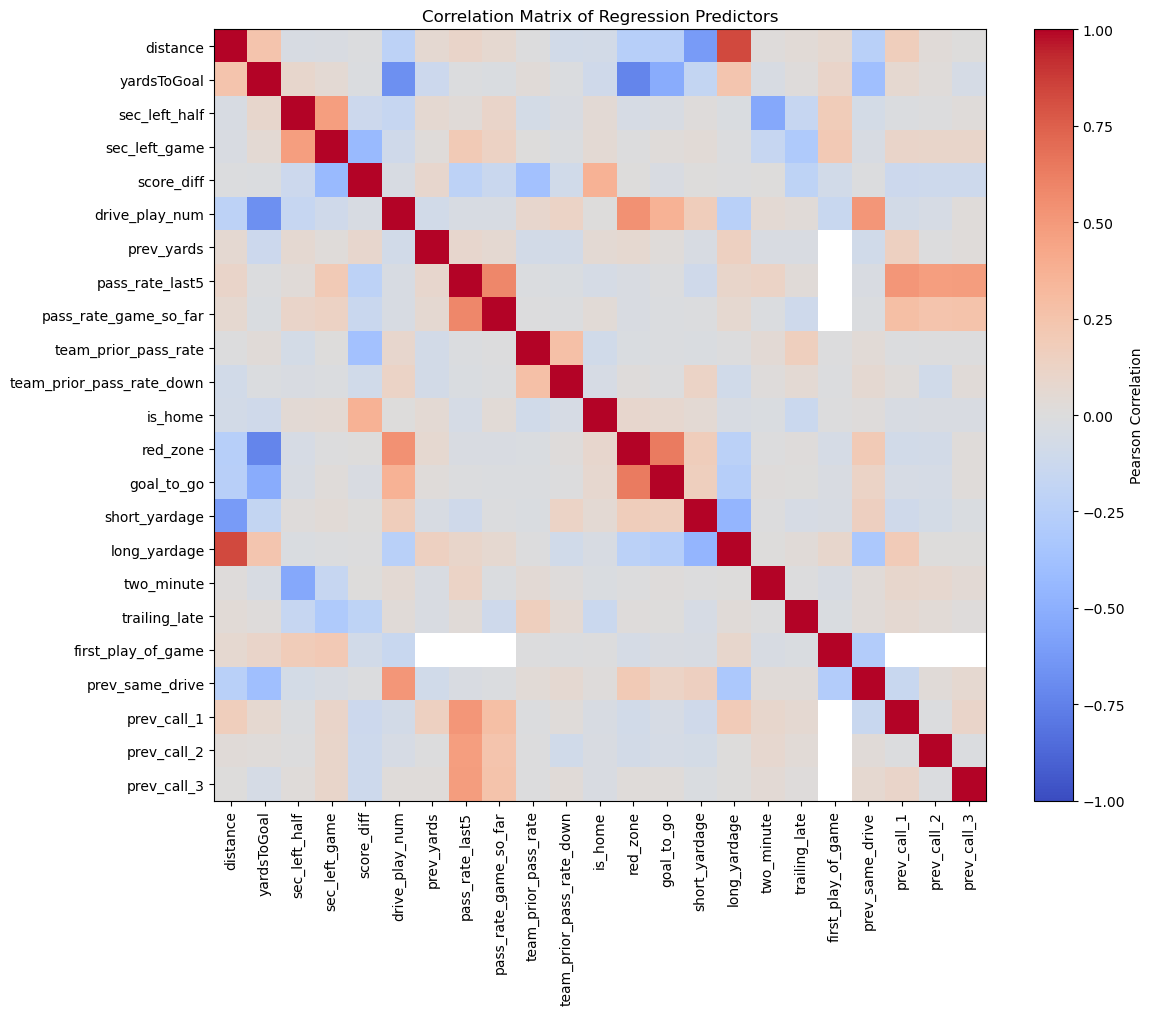

In [70]:

# Correlation matrix of numeric and binary regression predictors
corr_features = [
    f for f in num_f + bin_f
    if f in eda.columns
    and f not in [REG_TARGET, "is_pass", "yardsGained"] # yardsGained is post snap and should not be included
]

corr_matrix = eda[corr_features].corr(method="pearson")

plt.figure(figsize=(12, 10))

plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(corr_features)),
    corr_features,
    rotation=90
)

plt.yticks(
    range(len(corr_features)),
    corr_features
)

plt.title("Correlation Matrix of Regression Predictors")
plt.tight_layout()

plt.savefig(
    fig_dir / "regression_predictor_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [71]:

# Identify highly correlated regression predictor pairs

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

correlated_pairs = (
    upper.stack()
    .reset_index()
)

correlated_pairs.columns = [
    "feature_a",
    "feature_b",
    "correlation"
]

correlated_pairs["abs_correlation"] = (
    correlated_pairs["correlation"].abs()
)

correlated_pairs = (
    correlated_pairs[
        correlated_pairs["abs_correlation"] >= CORR_THRESHOLD
    ]
    .sort_values("abs_correlation", ascending=False)
    .reset_index(drop=True)
)

display(correlated_pairs)

,feature_a,feature_b,correlation,abs_correlation
0,distance,long_yardage,0.833113,0.833113
1,yardsToGoal,red_zone,-0.729141,0.729141
2,yardsToGoal,drive_play_num,-0.679380,0.679380
3,red_zone,goal_to_go,0.639158,0.639158
4,distance,short_yardage,-0.612556,0.612556


The correlation analysis identified four pairs of features with absolute Pearson correlations of at least 0.80. These relationships indicate potential redundancy among predictors.

### Feature selection

In [ ]:

def select_regression_features(
    data,
    features,
    corr_threshold=CORR_THRESHOLD,
    prefer_drop=None
):
    prefer_drop = prefer_drop or []

    # Separate numeric/binary features from nominal categories
    numeric_features = [
        f for f in features
        if f in (num_f + bin_f)
        and f in data.columns
    ]

    categorical_features = [
        f for f in features
        if f in cat_f
        and f in data.columns
    ]

    # Calculate predictor correlations
    corr = data[numeric_features].corr().abs()

    # Calculate individual association with PPA
    association = (
        data[numeric_features]
        .corrwith(data[REG_TARGET])
        .abs()
        .fillna(0)
    )

    kept = numeric_features.copy()
    dropped = []

    while True:
        current_corr = corr.loc[kept, kept].copy()

        # Ignore the diagonal
        np.fill_diagonal(current_corr.values, 0)

        if current_corr.empty or current_corr.max().max() < corr_threshold:
            break

        feature_a, feature_b = current_corr.stack().idxmax()

        # Apply preferred drop rules first
        if feature_a in prefer_drop:
            remove = feature_a
        elif feature_b in prefer_drop:
            remove = feature_b
        elif association[feature_a] >= association[feature_b]:
            remove = feature_b
        else:
            remove = feature_a

        kept.remove(remove)
        dropped.append(remove)

    # Add nominal categorical features back
    final_features = kept + categorical_features

    return final_features, dropped


In [74]:
# Regression candidate features
regression_candidates = [
    f for f in feature_cols
    if f in eda.columns
    and f not in [REG_TARGET, "is_pass", "yardsGained"]
]

regression_features, regression_dropped = (
    select_regression_features(
        data=eda,
        features=regression_candidates,
        corr_threshold=CORR_THRESHOLD,
        prefer_drop=PREFER_DROP
    )
)

print("Regression features retained:")
print(regression_features)

print("\nFeatures removed:")
print(regression_dropped)

print(f"\nNumber retained: {len(regression_features)}")
print(f"Number removed: {len(regression_dropped)}")

Regression features retained:
['distance', 'sec_left_half', 'sec_left_game', 'score_diff', 'drive_play_num', 'prev_yards', 'pass_rate_last5', 'pass_rate_game_so_far', 'team_prior_pass_rate', 'team_prior_pass_rate_down', 'is_home', 'goal_to_go', 'two_minute', 'trailing_late', 'first_play_of_game', 'prev_same_drive', 'prev_call_1', 'prev_call_2', 'prev_call_3', 'down', 'period']

Features removed:
['long_yardage', 'red_zone', 'yardsToGoal', 'short_yardage']

Number retained: 21
Number removed: 4


Regression feature selection was performed using PPA as the target variable. Numeric and binary predictors were evaluated based on their Pearson correlations with PPA, while highly correlated predictor pairs were identified using a correlation threshold of 0.80. When two predictors exceeded this threshold, the feature with the stronger individual association with PPA was retained, with preferred drop rules applied when specified. Four features were removed: long_yardage, red_zone, yardsToGoal, and short_yardage. The remaining 21 features were retained for regression model development.

In [75]:

regression_decisions = {
    "settings": {
        "CORR_THRESHOLD": CORR_THRESHOLD,
        "MAX_MISSING": MAX_MISSING,
        "PREFER_DROP": PREFER_DROP,
        "eda_split": "train",
        "target": REG_TARGET
    },

    "dropped": {
        "zero_variance": zero_var,
        "high_missing": high_missing,
        "correlated": regression_dropped,
    },

    "regression": {
        "features": regression_features,
        "categorical": [
            f for f in cat_f if f in regression_features
        ],
        "numeric": [
            f for f in num_f if f in regression_features
        ],
        "binary": [
            f for f in bin_f if f in regression_features
        ],
    },

    "targets": fl["targets"],
    "optional_categorical": fl.get("optional_categorical", []),
    "group_column": fl["group_column"],
    "split_column": fl["split_column"],
}

# Save regression feature-selection decisions
with open(
    processed_dir / "regression_feature_lists_after_eda.json", "w"
) as f:
    json.dump(regression_decisions, f, indent=2)

n_kept = len(regression_features)

print(
    f"Saved {processed_dir / 'regression_feature_lists_after_eda.json'}"
)
print(f"Regression features kept: {n_kept}")

# Report saved figures and tables
print("Figures:", len(list(fig_dir.glob("*.png"))), "in", fig_dir)
print("Tables:", len(list(table_dir.glob("*.csv"))), "in", table_dir)


Saved /Users/gracynkim/Desktop/school/fall '26/CSCI 6360/college-football-play-prediction/data/processed/regression_feature_lists_after_eda.json
Regression features kept: 21
Figures: 41 in /Users/gracynkim/Desktop/school/fall '26/CSCI 6360/college-football-play-prediction/reports/figures
Tables: 8 in /Users/gracynkim/Desktop/school/fall '26/CSCI 6360/college-football-play-prediction/reports/tables


## Blowout scenarios

A blowout is defined as a score differential of at least 28 points during the second half. Pass rates are compared between blowout and non-blowout situations. The number of plays occurring while trailing is also calculated to assess how much data is available for analyzing comeback scenarios.

In [ ]:
blowout = ((eda["score_diff"].abs() >= 28) & (eda["period"] >= 3)).rename("blowout (|lead| >= 28, 2nd half)")
print(eda.groupby(blowout)["is_pass"].agg(pass_rate="mean", plays="size").round(3))
print("\nPlays where the offense trails (score_diff < 0):", int((eda["score_diff"] < 0).sum()),
      f"({(eda['score_diff'] < 0).mean():.1%} of training plays) - few trailing plays means little data on comeback situations")

                                  pass_rate  plays
blowout (|lead| >= 28, 2nd half)                  
False                                 0.448   1213
True                                  0.313    182

Plays where the offense trails (score_diff < 0): 363 (26.0% of training plays) - few trailing plays means little data on comeback situations
